In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df=pd.read_csv('insurance.csv')
df

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520
...,...,...,...,...,...,...,...
1333,50,male,30.970,3,no,northwest,10600.54830
1334,18,female,31.920,0,no,northeast,2205.98080
1335,18,female,36.850,0,no,southeast,1629.83350
1336,21,female,25.800,0,no,southwest,2007.94500


In [3]:
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [4]:
df.tail()

,age,sex,bmi,children,smoker,region,charges
1333,50,male,30.97,3,no,northwest,10600.5483
1334,18,female,31.92,0,no,northeast,2205.9808
1335,18,female,36.85,0,no,southeast,1629.8335
1336,21,female,25.80,0,no,southwest,2007.9450
1337,61,female,29.07,0,yes,northwest,29141.3603


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


In [6]:
df.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


In [7]:
df.isnull().sum()

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

In [8]:
df.duplicated().sum()

1

In [9]:
df.drop_duplicates(inplace=True)

In [10]:
df.duplicated().sum()

0

In [11]:
df.dtypes

age           int64
sex          object
bmi         float64
children      int64
smoker       object
region       object
charges     float64
dtype: object

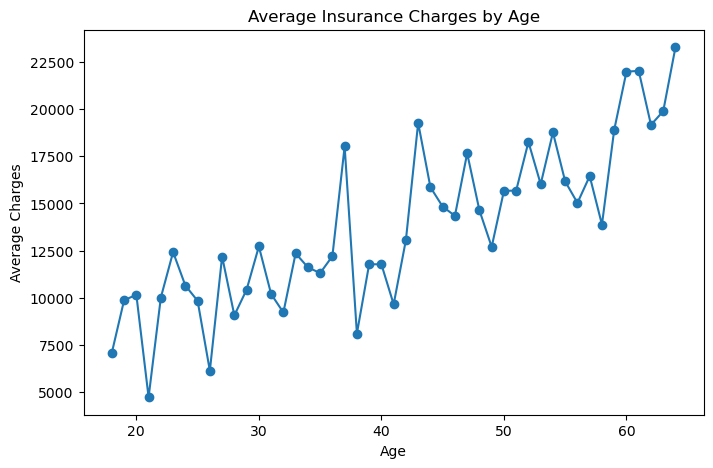

In [12]:
age_charges = df.groupby("age")["charges"].mean()

plt.figure(figsize=(8,5))
plt.plot(age_charges.index, age_charges.values, marker='o')
plt.xlabel("Age")
plt.ylabel("Average Charges")
plt.title("Average Insurance Charges by Age")
plt.show()

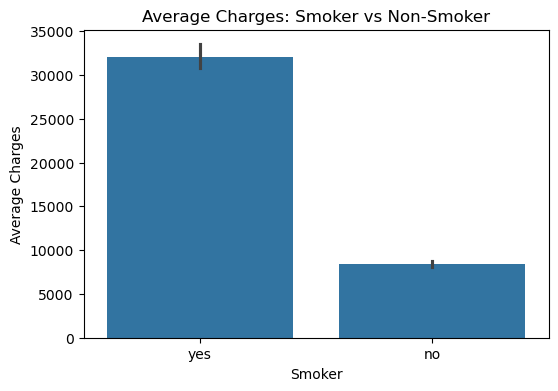

In [13]:
plt.figure(figsize=(6,4))
sns.barplot(x="smoker", y="charges", data=df)
plt.xlabel("Smoker")
plt.ylabel("Average Charges")
plt.title("Average Charges: Smoker vs Non-Smoker")
plt.show()


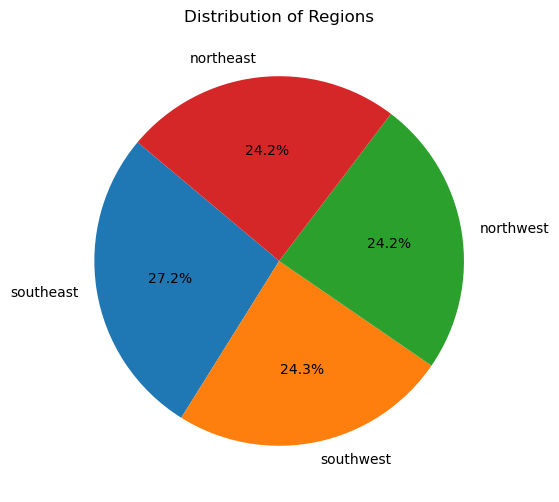

In [14]:
region_counts = df["region"].value_counts()

plt.figure(figsize=(6,6))
plt.pie(region_counts, labels=region_counts.index, autopct="%1.1f%%", startangle=140)
plt.title("Distribution of Regions")
plt.show()


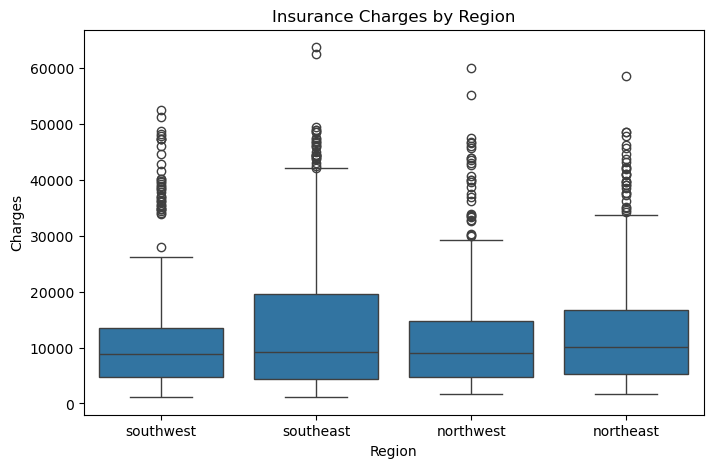

In [15]:
plt.figure(figsize=(8,5))
sns.boxplot(x="region", y="charges", data=df)
plt.xlabel("Region")
plt.ylabel("Charges")
plt.title("Insurance Charges by Region")
plt.show()


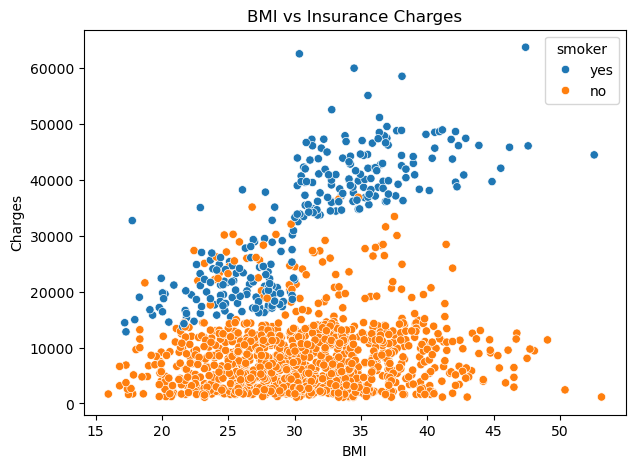

In [16]:
plt.figure(figsize=(7,5))
sns.scatterplot(x="bmi", y="charges", hue="smoker", data=df)
plt.xlabel("BMI")
plt.ylabel("Charges")
plt.title("BMI vs Insurance Charges")
plt.show()


In [17]:
from sklearn.preprocessing import LabelEncoder

# Initialize LabelEncoder
le_sex = LabelEncoder()
le_smoker = LabelEncoder()
le_region = LabelEncoder()

# Encode each column separately
df['sex'] = le_sex.fit_transform(df['sex'])
df['smoker'] = le_smoker.fit_transform(df['smoker'])
df['region'] = le_region.fit_transform(df['region'])




In [18]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1337 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1337 non-null   int64  
 1   sex       1337 non-null   int32  
 2   bmi       1337 non-null   float64
 3   children  1337 non-null   int64  
 4   smoker    1337 non-null   int32  
 5   region    1337 non-null   int32  
 6   charges   1337 non-null   float64
dtypes: float64(2), int32(3), int64(2)
memory usage: 67.9 KB


In [19]:
df.columns

Index(['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges'], dtype='object')

In [20]:
X=df[['age', 'sex', 'bmi', 'children', 'smoker', 'region']]
y=df['charges']

In [21]:
print(X.shape)
print(y.shape)


(1337, 6)
(1337,)


In [22]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)


In [23]:
from sklearn.ensemble import RandomForestRegressor

In [24]:
model = RandomForestRegressor(
    n_estimators=200,
    random_state=42
)

model.fit(X_train, y_train)


RandomForestRegressor(n_estimators=200, random_state=42)

In [25]:
y_pred = model.predict(X_test)

In [26]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
rf_r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("RMSE:", rmse)
print("R² Score:", rf_r2)


MAE: 2546.224652592164
RMSE: 4625.546730003947
R² Score: 0.8835647538322066


In [27]:
from sklearn.linear_model import LinearRegression

In [28]:
lr_model = LinearRegression()

lr_model.fit(X_train, y_train)


LinearRegression()

In [29]:
y_pred = lr_model.predict(X_test)


In [30]:


mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
lr_r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("RMSE:", rmse)
print("R² Score:", lr_r2)


MAE: 4182.353155288299
RMSE: 5957.608799816462
R² Score: 0.806846632262911


In [31]:
from sklearn.tree import DecisionTreeRegressor


In [32]:
dt_model = DecisionTreeRegressor(
    random_state=42
)

dt_model.fit(X_train, y_train)


DecisionTreeRegressor(random_state=42)

In [33]:
y_pred = dt_model.predict(X_test)


In [34]:

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
dt_r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("RMSE:", rmse)
print("R² Score:", dt_r2)


MAE: 2948.17890425
RMSE: 6339.107592617901
R² Score: 0.7813172300980598


In [35]:
from sklearn.svm import SVR
from sklearn.preprocessing import StandardScaler


In [36]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


In [37]:
svm_model = SVR(
    kernel='rbf',
    C=10,
    epsilon=0.1
)

svm_model.fit(X_train_scaled, y_train)


SVR(C=10)

In [38]:
y_pred = svm_model.predict(X_test_scaled)


In [39]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
svr_r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("RMSE:", rmse)
print("R² Score:", svr_r2)

MAE: 8883.711947215794
RMSE: 14107.826517616792
R² Score: -0.08312490305982934


In [40]:
from sklearn.ensemble import AdaBoostRegressor
from sklearn.tree import DecisionTreeRegressor

model = AdaBoostRegressor(
    estimator=DecisionTreeRegressor(max_depth=3),
    n_estimators=200,
    learning_rate=0.1,
    random_state=42
)


In [41]:
model.fit(X_train, y_train)


AdaBoostRegressor(estimator=DecisionTreeRegressor(max_depth=3),
                  learning_rate=0.1, n_estimators=200, random_state=42)

In [42]:
y_pred = model.predict(X_test)


In [43]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

ab_r2=r2_score(y_test, y_pred)

print("MAE:", mean_absolute_error(y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))
print("R²:", ab_r2)


MAE: 4302.684621158907
RMSE: 5041.891405515608
R²: 0.8616607888416324


In [44]:
from xgboost import XGBRegressor

In [45]:
xgb_model = XGBRegressor(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    objective='reg:squarederror',
    random_state=42
)


In [46]:
xgb_model.fit(X_train, y_train)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=0.8, device=None, early_stopping_rounds=None,
             enable_categorical=False, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=0.05, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=6,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=300,
             n_jobs=None, num_parallel_tree=None, ...)

In [47]:
y_pred = xgb_model.predict(X_test)

In [48]:
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
xgb_r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("RMSE:", rmse)
print("R² Score:", xgb_r2)


MAE: 2992.5311184247316
RMSE: 4806.019189146777
R² Score: 0.8743017240438884


In [49]:
from sklearn.ensemble import GradientBoostingRegressor

In [50]:
gb_model = GradientBoostingRegressor(
    n_estimators=300,      # number of boosting stages
    learning_rate=0.05,    # step size shrinkage
    max_depth=4,           # depth of each tree
    subsample=0.8,         # fraction of samples per tree
    random_state=42
)


In [51]:
gb_model.fit(X_train, y_train)

GradientBoostingRegressor(learning_rate=0.05, max_depth=4, n_estimators=300,
                          random_state=42, subsample=0.8)

In [52]:
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
gb_r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("RMSE:", rmse)
print("R² Score:", gb_r2)


MAE: 2992.5311184247316
RMSE: 4806.019189146777
R² Score: 0.8743017240438884


In [53]:
from sklearn.neighbors import KNeighborsRegressor

In [54]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


In [55]:
knn_model = KNeighborsRegressor(
    n_neighbors=5,      # number of neighbors
    weights='uniform',  # or 'distance'
    p=2                 # Euclidean distance (p=2)
)


In [56]:
knn_model.fit(X_train_scaled, y_train)


KNeighborsRegressor()

In [57]:
y_pred = knn_model.predict(X_test_scaled)


In [58]:
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
knn_r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("RMSE:", rmse)
print("R² Score:", knn_r2)


MAE: 3102.3946927873135
RMSE: 4989.340483900665
R² Score: 0.8645295403218781


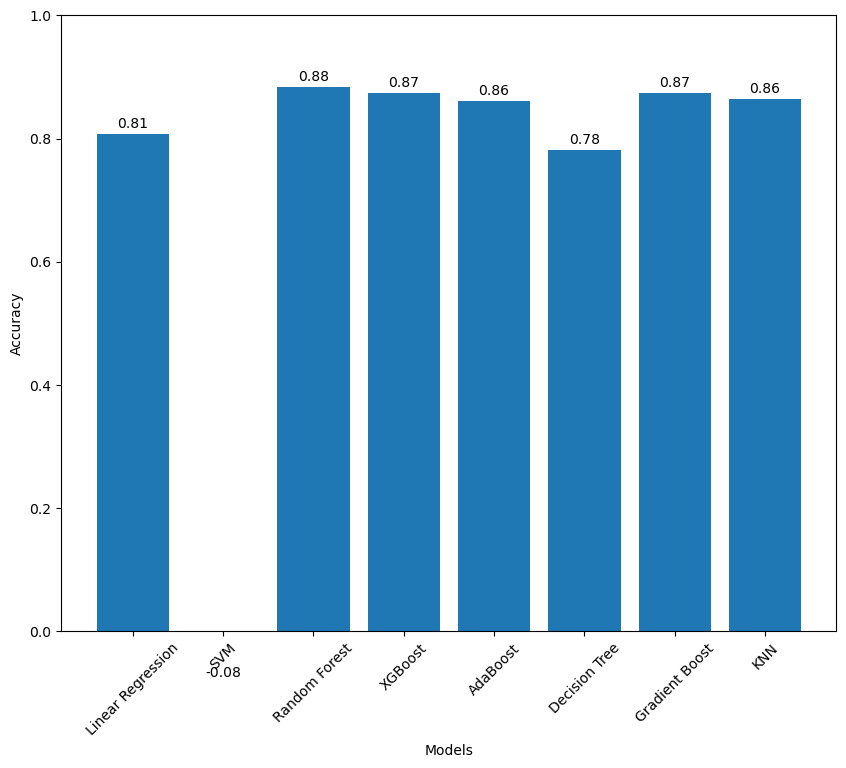

In [59]:
import matplotlib.pyplot as plt

models = [
    'Linear Regression',
    'SVM',
    'Random Forest',
    'XGBoost',
    'AdaBoost',
    'Decision Tree',
    'Gradient Boost',
    'KNN',
    
]

accuracies = [
    lr_r2,
    svr_r2,
    rf_r2,
    xgb_r2,
    ab_r2,
    dt_r2,
    gb_r2,
    knn_r2
]

plt.figure(figsize=(10,8))
plt.bar(models, accuracies)
plt.ylim(0,1)
plt.xticks(rotation=45)
plt.xlabel("Models")
plt.ylabel("Accuracy")


for i, v in enumerate(accuracies):
    plt.text(i, v + 0.01, f"{v:.2f}", ha='center')

plt.show()


In [61]:
import pickle

with open('le_sex.pkl', 'wb') as f:
    pickle.dump(le_sex, f)

with open('le_smoker.pkl', 'wb') as f:
    pickle.dump(le_smoker, f)

with open('le_region.pkl', 'wb') as f:
    pickle.dump(le_region, f)

with open('model.pkl', 'wb') as f:
    pickle.dump(xgb_model, f)

